# Visual 1: Value lost in its worst year

**Question.** In its worst calendar year since 2012, how much value did the U.S. dollar lose, and how much did Bitcoin lose?

- **Dollar:** change in buying power, from the Consumer Price Index, December to December.
- **Bitcoin:** change in price, last close of one year to last close of the next.

**Sources.** CPI from the Bureau of Labor Statistics via FRED. Bitcoin prices from Coin Metrics.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

FIRST_YEAR = 2012
LAST_YEAR = 2025

CPI_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=CPIAUCSL&cosd=2011-01-01"
BTC_URL = "https://raw.githubusercontent.com/coinmetrics/data/master/csv/btc.csv"

## 1. Load the data

In [2]:
cpi = pd.read_csv(CPI_URL)
cpi["date"] = pd.to_datetime(cpi["observation_date"])
cpi["year"] = cpi["date"].dt.year
cpi["month"] = cpi["date"].dt.month

btc = pd.read_csv(BTC_URL, usecols=["time", "PriceUSD"])
btc = btc.dropna()
btc["date"] = pd.to_datetime(btc["time"])
btc["year"] = btc["date"].dt.year

print("CPI rows:", len(cpi))
print("Bitcoin rows:", len(btc))

CPI rows: 190
Bitcoin rows: 5789


## 2. Yearly change for each

In [3]:
december_cpi = cpi[cpi["month"] == 12].set_index("year")["CPIAUCSL"]
year_end_price = btc.groupby("year")["PriceUSD"].last()

rows = []
for year in range(FIRST_YEAR, LAST_YEAR + 1):
    dollar_change = (december_cpi[year - 1] / december_cpi[year] - 1) * 100
    bitcoin_change = (year_end_price[year] / year_end_price[year - 1] - 1) * 100
    rows.append({"year": year, "dollar": dollar_change, "bitcoin": bitcoin_change})

yearly = pd.DataFrame(rows).set_index("year")
yearly.round(1)

,dollar,bitcoin
year,,
2012,-1.7,187.3
2013,-1.5,5286.0
2014,-0.6,-56.0
2015,-0.6,34.0
2016,-2.0,125.5
2017,-2.1,1336.7
2018,-2.0,-73.5
2019,-2.3,94.4
2020,-1.3,304.9


## 3. The two numbers

In [4]:
dollar_year = yearly["dollar"].idxmin()
dollar_loss = -yearly["dollar"].min()

bitcoin_year = yearly["bitcoin"].idxmin()
bitcoin_loss = -yearly["bitcoin"].min()

dollar_down_years = (yearly["dollar"] < 0).sum()
bitcoin_down_years = (yearly["bitcoin"] < 0).sum()

print(f"Dollar's worst year: {dollar_year}, lost {dollar_loss:.1f}%")
print(f"Bitcoin's worst year: {bitcoin_year}, lost {bitcoin_loss:.1f}%")
print(f"Years the dollar lost buying power: {dollar_down_years} of {len(yearly)}")
print(f"Years Bitcoin's price fell: {bitcoin_down_years} of {len(yearly)}")

Dollar's worst year: 2021, lost 6.7%
Bitcoin's worst year: 2018, lost 73.5%
Years the dollar lost buying power: 14 of 14
Years Bitcoin's price fell: 4 of 14


## 4. The chart

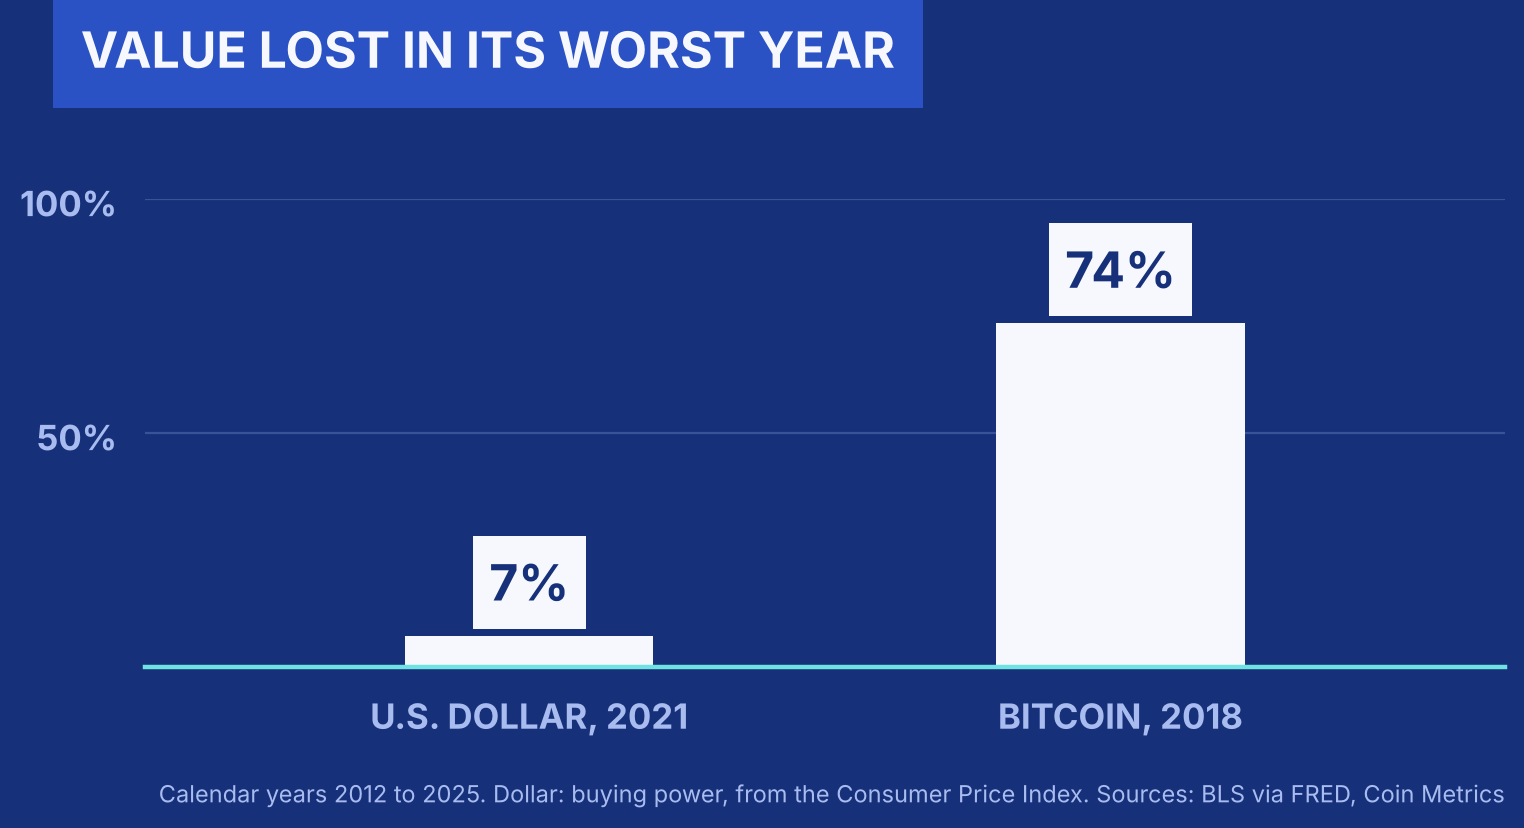

In [5]:
BLUE = "#16307a"
PANEL = "#2a52c4"
WHITE = "#f6f8fd"
AQUA = "#6fe3e1"
SOFT = "#a9bcf0"

labels = [f"U.S. DOLLAR, {dollar_year}", f"BITCOIN, {bitcoin_year}"]
losses = [dollar_loss, bitcoin_loss]

plt.rcParams["font.weight"] = "bold"

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=200)
fig.set_facecolor(BLUE)
ax.set_facecolor(BLUE)

ax.bar(labels, losses, width=0.42, color=WHITE)

for i in range(len(losses)):
    ax.text(i, losses[i] + 5, f"{losses[i]:.0f}%", ha="center", va="bottom",
            fontsize=18, color=BLUE, bbox={"facecolor": WHITE, "edgecolor": "none", "pad": 6})

ax.set_ylim(0, 100)
ax.set_yticks([50, 100])
ax.set_yticklabels(["50%", "100%"])
ax.set_xlim(-0.65, 1.65)
ax.tick_params(length=0, colors=SOFT, labelsize=12.5, pad=10)
ax.grid(axis="y", color=SOFT, alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color(AQUA)
ax.spines["bottom"].set_linewidth(1.6)

fig.text(0.06, 0.9, "VALUE LOST IN ITS WORST YEAR", fontsize=18, color=WHITE, va="top",
         bbox={"facecolor": PANEL, "edgecolor": "none", "pad": 10})
fig.text(0.95, 0.03, f"Calendar years {FIRST_YEAR} to {LAST_YEAR}. Dollar: buying power, from the "
         "Consumer Price Index. Sources: BLS via FRED, Coin Metrics",
         fontsize=8.5, color=SOFT, ha="right", fontweight="normal")

fig.subplots_adjust(left=0.10, right=0.95, top=0.70, bottom=0.18)
fig.savefig("visual1_worst_year.png", facecolor=BLUE)
plt.show()

## What the chart leaves out

- **Bitcoin's gains.** The chart shows each one's worst year only. Bitcoin rose in most years.
- **Interest.** Buying power treats the dollar as cash that earns nothing.
- **The current year.** Only complete years are counted.